In [1]:
from collections import Counter
import pandas as pd
from sklearn.cluster import AgglomerativeClustering
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import sklearn
from sklearn.ensemble import RandomForestClassifier
import shap

data = pd.read_excel(r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage5_deybe\296×87.xlsx")
X = data.iloc[:, 3:]
X
feature_names = X.columns
X = StandardScaler().fit_transform(X)

min_val = np.min(X, axis=0)
max_val = np.max(X, axis=0)
X = (X - min_val) / (max_val - min_val)
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(X)
X.shape

(296, 87)

In [2]:

def extract_numbers(file_path):
    df = pd.read_excel(file_path)
    valid_numbers = []
    for index, value in df['composition'].items():
        if not pd.isna(value):
            valid_numbers.append(int(df.at[index, 'number']))
    return valid_numbers

file_path = r"E:\desktop\Multiobjective Identification of Phosphor Materials via a Domain Knowledge Integrated Semisupervised Learning Framework\dataset\stage5_deybe\benchmark5.xlsx"
reported_structures = extract_numbers(file_path)

In [3]:
pca = PCA(n_components= 0.3, random_state=42)
new_data = pca.fit_transform(X)
print(new_data.shape)
ratios = pca.explained_variance_ratio_
components = pca.components_
X = pd.DataFrame(X)

components_df = pd.DataFrame(
    components,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(components.shape[0])]
)

output_file = "pca_components.xlsx"
components_df.to_excel(output_file, index=True)


i = 6
model = AgglomerativeClustering(n_clusters= i, metric = 'cosine', linkage = 'average')
model = model.fit(new_data)
labels = model.labels_

df = pd.DataFrame(labels)
df.to_excel("ward_result_1.xlsx", index=False)

data[f'cluster_{i}'] = labels

print(f"\nNumber of clusters k={i}:")
print(f"\nSilhouette score: {silhouette_score(new_data, labels):.2f}", f"\nCalinski-Harabasz score: {calinski_harabasz_score(new_data, labels):.2f}")
label_1 = []
for num  in  reported_structures:
        label = labels[num-1]
        label_1.append(int(label))
print(label_1)


for cluster in range(i):

    cluster_samples = data[data[f'cluster_{i}'] == cluster]
            # print(cluster_samples)

    total_in_cluster = len(cluster_samples)
    print(total_in_cluster)

    reported_in_cluster = len([num for num in cluster_samples['number'] if num in reported_structures])

    print(f"Cluster {cluster}: {reported_in_cluster}/{total_in_cluster} "
                f"(Reported ratio: {reported_in_cluster/total_in_cluster:.2%})")


(296, 2)

Number of clusters k=6:

Silhouette score: 0.38 
Calinski-Harabasz score: 322.46
[2, 2, 2, 5, 2, 0, 5, 0, 0, 1, 2, 5, 3, 2, 2]
66
Cluster 0: 3/66 (Reported ratio: 4.55%)
13
Cluster 1: 1/13 (Reported ratio: 7.69%)
95
Cluster 2: 7/95 (Reported ratio: 7.37%)
39
Cluster 3: 1/39 (Reported ratio: 2.56%)
26
Cluster 4: 0/26 (Reported ratio: 0.00%)
57
Cluster 5: 3/57 (Reported ratio: 5.26%)


In [4]:


clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(new_data, labels)

print(f"Training fidelity accuracy: {clf.score(new_data, labels):.2f}")

# ============================================================
# RF surrogate classifier fidelity evaluation


# ============================================================
from collections import Counter
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

class_counts = Counter(labels)
min_class_count = min(class_counts.values())
n_splits = min(5, min_class_count)

if n_splits < 2:
    raise ValueError(
        f"The smallest class contains {min_class_count} samples, so at least 2-fold stratified cross-validation is not possible."
    )

print("\n========== RF surrogate classifier fidelity evaluation ==========")
print("Samples per cluster:", {k: v for k, v in sorted(class_counts.items())})
print(f"Using stratified {n_splits}-fold cross-validation")

rf_cv = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Macro-F1": "f1_macro",
    "Balanced Accuracy": "balanced_accuracy"
}

cv_results = cross_validate(
    rf_cv,
    new_data,
    labels,
    cv=StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    ),
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

print("\nCross-validation results (mean ± std):")
for metric_name in scoring:
    scores = cv_results[f"test_{metric_name}"]
    print(f"{metric_name}: {scores.mean():.4f} ± {scores.std(ddof=1):.4f}")

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

oof_pred = cross_val_predict(
    rf_cv,
    new_data,
    labels,
    cv=cv,
    n_jobs=-1
)

oof_acc = accuracy_score(labels, oof_pred)
oof_macro_f1 = f1_score(labels, oof_pred, average="macro")
oof_bal_acc = balanced_accuracy_score(labels, oof_pred)

print("\nOverall OOF evaluation:")
print(f"OOF Accuracy:          {oof_acc:.4f}")
print(f"OOF Macro-F1:          {oof_macro_f1:.4f}")
print(f"OOF Balanced Accuracy: {oof_bal_acc:.4f}")

print("\nClassification report:")
print(classification_report(
    labels,
    oof_pred,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(labels, oof_pred))






Training fidelity accuracy: 1.00

========== RF surrogate classifier fidelity evaluation ==========
Samples per cluster: {np.int64(0): 66, np.int64(1): 13, np.int64(2): 95, np.int64(3): 39, np.int64(4): 26, np.int64(5): 57}
Using stratified 5-fold cross-validation

Cross-validation results (mean ± std):
Accuracy: 0.9661 ± 0.0268
Macro-F1: 0.9543 ± 0.0377
Balanced Accuracy: 0.9491 ± 0.0440

Overall OOF evaluation:
OOF Accuracy:          0.9662
OOF Macro-F1:          0.9549
OOF Balanced Accuracy: 0.9460

Classification report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        66
           1     1.0000    0.8462    0.9167        13
           2     0.9579    0.9579    0.9579        95
           3     0.9487    0.9487    0.9487        39
           4     0.9231    0.9231    0.9231        26
           5     0.9661    1.0000    0.9828        57

    accuracy                         0.9662       296
   macro avg     0.9660    0.9460  

In [5]:


explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(new_data)
print(shap_values.shape)

(296, 2, 6)


Generating the global importance analysis for Cluster 2 and saving it as PDF...


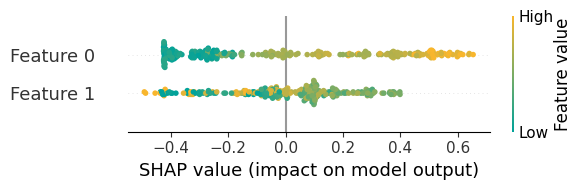

Saved: Cluster2_Summary_Plot.pdf


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import shap
import matplotlib.colors as mcolors


shap_array = np.array(shap_values)




cluster_4_values = shap_array[:, :new_data.shape[1], 2]


fixed_width = 6
fixed_height = 2



custom_colors = ["#00A29A", "#F8B62D"]
custom_cmap = mcolors.LinearSegmentedColormap.from_list("custom_shap_cmap", custom_colors)


print("Generating the global importance analysis for Cluster 2 and saving it as PDF...")


plt.figure(facecolor='white')


shap.summary_plot(
    cluster_4_values,
    new_data,
    plot_size=(fixed_width, fixed_height),
    cmap=custom_cmap,
    show=False
)

fig = plt.gcf()
fig.set_facecolor('white')



plt.savefig("Cluster2_Summary_Plot.pdf", bbox_inches='tight', facecolor='white')


plt.show()

print("Saved: Cluster2_Summary_Plot.pdf")